Average Temperature for Each Crime:
                            CrimeType    AvgTemp
0                            GAMBLING  63.767606
1                    PUBLIC INDECENCY  62.090909
2                   HUMAN TRAFFICKING  56.633333
3                LIQUOR LAW VIOLATION  55.368534
4   CONCEALED CARRY LICENSE VIOLATION  54.940092
5                            HOMICIDE  54.569882
6    INTERFERENCE WITH PUBLIC OFFICER  53.483829
7                   WEAPONS VIOLATION  53.159410
8                        PROSTITUTION  53.024229
9              PUBLIC PEACE VIOLATION  52.674342
10                    CRIMINAL DAMAGE  52.561186
11            CRIMINAL SEXUAL ASSAULT  52.237683
12                            BATTERY  52.139467
13                            ASSAULT  52.052522
14                            ROBBERY  51.869043
15                              ARSON  51.732000
16                       INTIMIDATION  51.714724
17                              THEFT  51.617727
18                           BURG

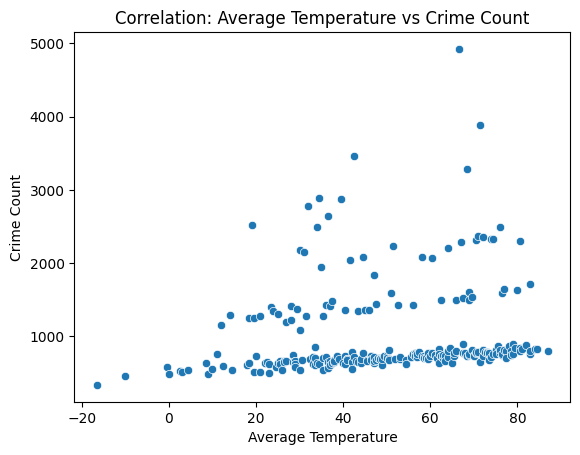

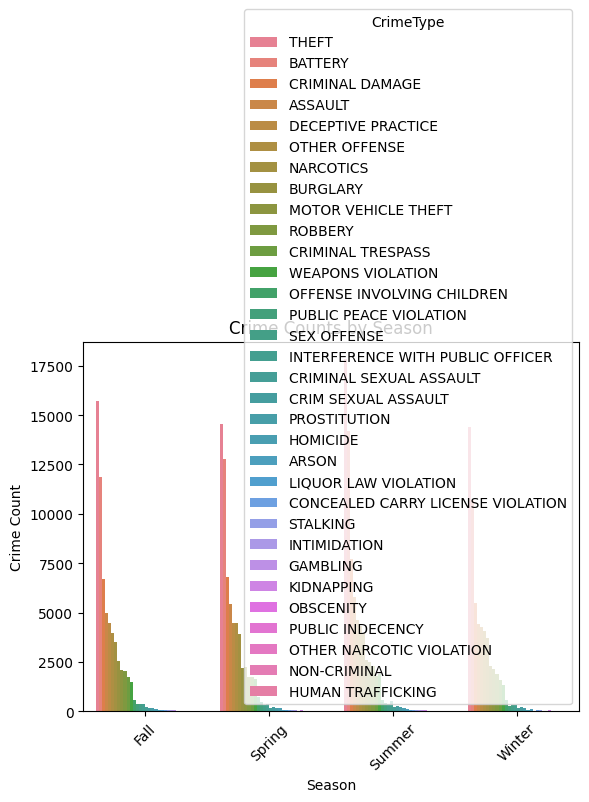

In [15]:
import pandas as pd
import sqlite3
import seaborn as sns
import matplotlib.pyplot as plt

# Load Crime Data (2019)
crime_data = pd.read_csv('Crimes_-_2019_20231112.csv')

# Clean Crime Data
crime_data = crime_data[['Date', 'Primary Type', 'Location Description', 'District', 'Community Area']]
crime_data['Date'] = pd.to_datetime(crime_data['Date'], errors='coerce')
crime_data['Year'] = crime_data['Date'].dt.year
crime_data_2019 = crime_data[crime_data['Year'] == 2019].drop(columns=['Year'])
crime_data_2019.dropna(inplace=True)

# Load Weather Data (2018-2023)
weather_data = pd.read_csv('chicago_temps_18-23.csv')
weather_data.rename(columns={'weather_date': 'Date'}, inplace=True)
weather_data['Date'] = pd.to_datetime(weather_data['Date'], errors='coerce')
weather_data['Year'] = weather_data['Date'].dt.year
weather_data_2019 = weather_data[weather_data['Year'] == 2019].drop(columns=['Year'])
weather_data_2019.dropna(inplace=True)

# Adjust Date Columns to Match Granularity
crime_data_2019['Date'] = crime_data_2019['Date'].dt.date
weather_data_2019['Date'] = weather_data_2019['Date'].dt.date

# Create SQL Database
conn = sqlite3.connect(':memory:')
crime_data_2019.to_sql('Crime', conn, index=False, if_exists='replace')
weather_data_2019.to_sql('Weather', conn, index=False, if_exists='replace')

# 1. Find Average Temperature for Each Crime
query_avg_temp = """
    SELECT 
        c.`Primary Type` AS CrimeType, 
        AVG(w.average) AS AvgTemp
    FROM Crime c
    LEFT JOIN Weather w ON c.Date = w.Date
    GROUP BY c.`Primary Type`
    ORDER BY AvgTemp DESC
"""
avg_temp_per_crime = pd.read_sql_query(query_avg_temp, conn)
print("Average Temperature for Each Crime:")
print(avg_temp_per_crime)

# 2. Count Crimes in Different Temperature Segments
query_temp_segments = """
    SELECT 
        c.`Primary Type` AS CrimeType,
        CASE 
            WHEN w.average < 50 THEN 'Cold'
            WHEN w.average BETWEEN 50 AND 75 THEN 'Moderate'
            ELSE 'Hot'
        END AS TempSegment,
        COUNT(*) AS CrimeCount
    FROM Crime c
    LEFT JOIN Weather w ON c.Date = w.Date
    GROUP BY c.`Primary Type`, TempSegment
    ORDER BY CrimeType, TempSegment
"""
crime_by_temp_segment = pd.read_sql_query(query_temp_segments, conn)
print("Crimes in Different Temperature Segments:")
print(crime_by_temp_segment)

# 3. Correlation Between Weather and Crime Count
query_correlation = """
    SELECT 
        AVG(w.average) AS AvgTemp,
        AVG(w.precipitation) AS AvgPrecipitation,
        COUNT(c.`Primary Type`) AS CrimeCount
    FROM Crime c
    LEFT JOIN Weather w ON c.Date = w.Date
    GROUP BY w.average, w.precipitation
    ORDER BY AvgTemp
"""
correlation_data = pd.read_sql_query(query_correlation, conn)
print("Correlation Between Weather and Crime Count:")
print(correlation_data)

# 4. Season-Wise Crime Analysis
query_season_analysis = """
    SELECT 
        c.`Primary Type` AS CrimeType,
        CASE 
            WHEN strftime('%m', c.Date) IN ('12', '01', '02') THEN 'Winter'
            WHEN strftime('%m', c.Date) IN ('03', '04', '05') THEN 'Spring'
            WHEN strftime('%m', c.Date) IN ('06', '07', '08') THEN 'Summer'
            WHEN strftime('%m', c.Date) IN ('09', '10', '11') THEN 'Fall'
        END AS Season,
        COUNT(*) AS CrimeCount
    FROM Crime c
    GROUP BY Season, c.`Primary Type`
    ORDER BY Season, CrimeCount DESC
"""
season_analysis = pd.read_sql_query(query_season_analysis, conn)
print("Season-Wise Crime Analysis:")
print(season_analysis)

# 5. Visualize Correlation: Average Temperature vs Crime Count
sns.scatterplot(data=correlation_data, x='AvgTemp', y='CrimeCount')
plt.title("Correlation: Average Temperature vs Crime Count")
plt.xlabel("Average Temperature")
plt.ylabel("Crime Count")
plt.show()

# 6. Visualize Season-Wise Crime Trends
sns.barplot(data=season_analysis, x='Season', y='CrimeCount', hue='CrimeType')
plt.title("Crime Counts by Season")
plt.ylabel("Crime Count")
plt.xlabel("Season")
plt.xticks(rotation=45)
plt.show()

# Close the database connection
conn.close()